# Notebook 03 - Chapter 3

Below you find exercises for Chapter 3. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

Transform-based option pricing methods like the Laplace transform approach are useful tools to obtain option prices in many different more sophisticated models because often the characteristic function of the log-stock price is known in closed form, while its density is not. The fast Fourier transform is particularly useful because it can be employed to simultaneously compute the prices of options with multiple different strike prices. In this notebook we are applying these methods to the Heston model from Section 2.5. In the code snippet below, we define the variables $r$, $\gamma(0)$, $\kappa$ $\lambda$, $\widetilde \sigma$, $\rho$, $T$ and $S(0)$ for the model.

In [1]:
import os
import marshal
import types
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm
from scipy.integrate import quad, dblquad
import pandas as pd
from scipy.optimize import minimize
from scipy.optimize.elementwise import find_root
from scipy.special import wofz
from IPython.display import clear_output
warnings.simplefilter("ignore")
print(os.getcwd())

r = 0.02
gam0 = 0.3**2
kappa = 0.3**2
lamb = 2.5
sig_tilde = 0.3
rho = -0.5
T = 1
S0 = 120

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br><br>

## Step 1: Computing option prices via the Laplace transform

Transform methods like the Laplace transform or the Fourier transform are a useful tool to compute the prices of options in models with known characteristic function. This is for example the case in the Heston model, in which no closed analytical formulas for computing option prices exist. In this notebook we will use the Heston model in its full form, i.e. without the simplifying assumption made in Section 2.5 of uncorrelated Brownian motions driving the stock and the stochastic volatility. Therefore, besides the parameters $\kappa$, $\lambda$ and $\widetilde\sigma$ there is an additional correlation parameter $\rho$ in the Heston model such that $d[W, \widetilde W](t) = \rho dt$.

The code snippet below contains a function `heston_char` with a stable implementation of the characteristic function $\chi_t(u) = \exp(\psi_0(t) + \psi_1(t) \log(S(t)) + \psi_2(t)\gamma(t))$ of $\log S(T)$ in the Heston model with parameters $\kappa$, $\lambda$, $\widetilde \sigma$ and $\rho$, current variance $\gamma(t)$, current stock price $S(t)$ and risk-free interest rate $r$ which is based on a paper by Albrecher, Mayer, Schoutens and Tistaert from 2007. Defining $B = \rho \widetilde{\sigma} u i - \lambda$, $D = \sqrt{B^2 + \widetilde\sigma^2 u (u + i)}$ and $G(t) = B \frac{e^{-D(T - t)} - 1}{2D} + \frac{e^{-D(T-t)} + 1}{2}$, this formula differs from the formula given in equation (3.8) in the lecture notes only in
\begin{align*}
\psi_0(t) &= i u r(T - t) - \frac{\kappa}{\widetilde \sigma^2} \big((B + D)(T - t) + 2 \log(G(t))\big) \\
\psi_2(t) &=  \frac{u(u + i) (e^{-D(T-t)} - 1)}{B (e^{-D(T - t)} - 1) + D(e^{-D (T - t)} + 1)}.
\end{align*}

In [2]:
def heston_char(u, St, t, T, r, gamt, kappa, lamb, sig_tilde, rho):
    B = rho * sig_tilde * u * 1j - lamb
    D = np.sqrt(B**2 + sig_tilde**2 * u * (u + 1j))
    lnG = np.log(B * (np.exp(-D * (T - t)) - 1) / (2 * D) + (np.exp(-D * (T - t)) + 1) / 2)
    psi_0 = u * 1j * r * (T - t) - kappa / sig_tilde**2 * ((B + D) * (T - t) + 2 * lnG) 
    psi_1 = u * 1j
    psi_2 = u * (u + 1j) * (np.exp(-D * (T - t)) - 1) / (B * (np.exp(-D * (T - t)) - 1) + D * (np.exp(-D * (T - t)) + 1))
    return np.exp(psi_0 + psi_1 * np.log(St) + psi_2 * gamt)

Our goal is now to use option pricing via the Laplace transform to compute call option prices in the Heston model for multiple different values of the strike $K$.

**Task 1.1**: Let $R$ be the constant from equation (3.4) in the lecture notes. Define a variable `R` containing an appropriate value for $R$ to price call options. Define an array `K_arr` that contains 100 equally spaced values of the strike $K$ between 50 and 300.

*Useful Python commands*: `np.linspace`

In [3]:
R = 1.5
K_arr = np.linspace(50, 300, 100)

### Uncomment and execute the following line only if you obtained no result:
#K_arr1 = np.loadtxt('../shared_materials/objects/2_1_3.txt')
print(K_arr)
#print(K_arr1)

#print(np.array_equal(K_arr, K_arr1))

[ 50.          52.52525253  55.05050505  57.57575758  60.1010101
  62.62626263  65.15151515  67.67676768  70.2020202   72.72727273
  75.25252525  77.77777778  80.3030303   82.82828283  85.35353535
  87.87878788  90.4040404   92.92929293  95.45454545  97.97979798
 100.50505051 103.03030303 105.55555556 108.08080808 110.60606061
 113.13131313 115.65656566 118.18181818 120.70707071 123.23232323
 125.75757576 128.28282828 130.80808081 133.33333333 135.85858586
 138.38383838 140.90909091 143.43434343 145.95959596 148.48484848
 151.01010101 153.53535354 156.06060606 158.58585859 161.11111111
 163.63636364 166.16161616 168.68686869 171.21212121 173.73737374
 176.26262626 178.78787879 181.31313131 183.83838384 186.36363636
 188.88888889 191.41414141 193.93939394 196.46464646 198.98989899
 201.51515152 204.04040404 206.56565657 209.09090909 211.61616162
 214.14141414 216.66666667 219.19191919 221.71717172 224.24242424
 226.76767677 229.29292929 231.81818182 234.34343434 236.86868687
 239.393939

**Task 1.2**: Define a function `f_tilde(z, K)` that computes the Laplace transform of the call option payoff $(e^x - K)^+$ with strike `K`.

In [4]:
def f_tilde(z, K): 
    return (K ** (1 - z)) / (z * (z - 1))


print(f_tilde(124, 150)) # OK

### Uncomment and execute the following line only if you obtained no result:
f_tilde1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_1_2.mar', 'rb')), globals())
print(f_tilde1(124, 150)) # gleich

1.4369721116451653e-272
1.4369721116451653e-272


We now want to measure the time that the Laplace pricing approach takes to compute the call option prices for the 100 different strikes. Therefore, we write the command `%%time` at the beginning of the code cell.

**Task 1.3**: Use a for-loop to compute the prices $V(0)$ of European call options in the Heston model with parameters as above for the strikes $K$ taking values in `K_array`. In each iteration of the loop you should

- Use your functions `f_tilde` and `heston_char` to define the integrand from equation (3.4) as a Python function of the variable $u$.
- Use the scipy.integrate function `quad` to evaluate the integral (3.4). (The integral $\int_a^b f(u) du$ can be computed via the command `quad(f, a, b)[0]`. `a` or `b` can also be set to `np.inf`).

Store the different prices in an array `call_Heston_Laplace`.

*Useful Python commands*: `np.real`, `np.exp`

In [5]:
%%time

call_Heston_Laplace = np.zeros(100)

for i, K in enumerate(K_arr):

    def integrand(u):
            real =  np.real(f_tilde(R + 1j * u, K) * heston_char(u - 1j * R, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho))
            return real

    call_Heston_Laplace[i] = np.exp(-r * T) / np.pi * quad(integrand, 0, np.inf)[0]

print(call_Heston_Laplace)

### Uncomment and execute the following line only if you obtained no result:
#call_Heston_Laplace1 = np.loadtxt('../shared_materials/objects/3_1_3.txt')
#print(np.array_equal(call_Heston_Laplace, call_Heston_Laplace1)) # True

[7.10030105e+01 6.85346823e+01 6.60693273e+01 6.36079291e+01
 6.11517007e+01 5.87021131e+01 5.62609224e+01 5.38301937e+01
 5.14123210e+01 4.90100417e+01 4.66264447e+01 4.42649701e+01
 4.19293997e+01 3.96238389e+01 3.73526864e+01 3.51205939e+01
 3.29324150e+01 3.07931429e+01 2.87078388e+01 2.66815517e+01
 2.47192313e+01 2.28256363e+01 2.10052411e+01 1.92621425e+01
 1.75999714e+01 1.60218102e+01 1.45301223e+01 1.31266931e+01
 1.18125878e+01 1.05881265e+01 9.45287793e+00 8.40567329e+00
 7.44463821e+00 6.56724283e+00 5.77036733e+00 5.05038013e+00
 4.40322564e+00 3.82451785e+00 3.30963610e+00 2.85381940e+00
 2.45225616e+00 2.10016658e+00 1.79287552e+00 1.52587448e+00
 1.29487183e+00 1.09583119e+00 9.24998372e-01 7.78917631e-01
 6.54438521e-01 5.48714613e-01 4.59195597e-01 3.83614195e-01
 3.19969286e-01 2.66506477e-01 2.21697220e-01 1.84217375e-01
 1.52925935e-01 1.26844491e-01 1.05137806e-01 8.70957814e-02
 7.21169664e-02 5.96936623e-02 4.93986314e-02 4.08733462e-02
 3.38176937e-02 2.798102

**Task 1.4**: Plot the option prices from the array `call_Heston_Laplace` against the strike prices from the array `K_arr`.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_1_4.png" width="550">
</details>

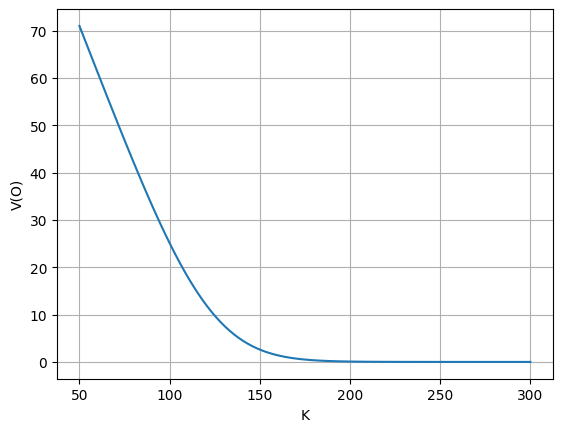

In [7]:
plt.plot(K_arr, call_Heston_Laplace)
plt.ylabel('V(O)')
plt.xlabel('K')
plt.grid()
plt.show()

<br>

## Step 2: Computing option prices via the fast Fourier transform

Computing option prices via the fast Fourier transform as in Section 3.2 of the lecture notes has the advantage that this method is tailor-made for simultaneously calculating option prices with many different strikes, as we did in Step 1 with the Laplace transform. We would now like to see how much faster the fast Fourier transform performs this task.

**Task 2.1**: Write a function `g(u)` that computes the function $g$ from equation (3.13) in the lecture notes with $t = 0$ as a function of $u$ in the Heston model with parameters as before.

In [8]:
def f_k_tilde(z, kappa):
    return np.exp((1 - z) * kappa) / (z * (z - 1))

def g(u):
    return f_k_tilde((R + (1j * u)), kappa = 0) * heston_char(u - 1j * R, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho)

print(g(274)) # (-6.419455151103594e-62-1.38328743726929e-61j) OK

### Uncomment and execute the following line only if you obtained no result:
# g1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_2_1.mar', 'rb')), globals())
# print(g1(274)) # (-6.419455151103594e-62-1.38328743726929e-61j)

(-6.419455151103594e-62-1.38328743726929e-61j)


**Task 2.2**: Let $M = 5000$ and $N = 2^{15}$. Define an array `n` that contains the integers $1, 2, \dots, N$. Moreover, define an array `kappa_m` that contains the values $\kappa_m$ for $m \in \{1, \dots, N\}$ from equation (3.15) with $\kappa_1 := \log(50) =$ `np.log(K_arr[0])`.

*Useful Python commands*: `np.arange`, `np.linspace`

In [9]:
M = 5000
N = 2 ** 15 # 2 ** 15
kappa1 = np.log(K_arr[0])

n = np.arange(1, N+1)
kappa_m = kappa1 + (n - 1) * 2 * np.pi / M
print(len(n))
print(len(kappa_m))

### Uncomment and execute the following line only if you obtained no result:
n1, kappa_m1 = np.loadtxt('../shared_materials/objects/3_2_2.txt')
# print(np.round(kappa_m, 10) == np.round(kappa_m1, 10)) # True
print(len(n1))
print(len(kappa_m1))

32768
32768
65536
65536


**Task 2.3**: Define an array `x` that contains the values $x_n$ for $n \in \{1, \dots, N\}$ from equation (3.17). Afterwards, use the function `np.fft.fft` to compute the discrete Fourier transform $\widehat x_m$, $m \in \{1, \dots, N\}$ via the fast Fourier transform algorithm and store it in an array `x_hat`.

*Useful Python commands*: `np.exp`, `np.log`

In [10]:
delta = M/N
print(delta)
x = g((n - 0.5) * delta) * delta * np.exp(-1j * (n - 1) * delta * kappa1)

print(x)
x_hat = np.fft.fft(x)
# print(len(x_hat)) #32768

print(x_hat)

### Uncomment and execute the following line only if you obtained no result:
#x1, x_hat1 = np.loadtxt('../shared_materials/objects/3_2_3.txt')
#print(x1)
#print(x_hat1)
#pd.DataFrame(x_hat1)

0.152587890625
[273.53650964+46.53368204j 251.78834233-16.48976071j
 209.57607435-51.47678973j ...   0.         +0.j
   0.         +0.j          -0.         +0.j        ]
[1751.51630537-220.80092981j 1751.66543158-222.35057861j
 1751.8124096 -223.9018592j  ... 1751.05610448-216.16178476j
 1751.21163516-217.70653185j 1751.36503767-219.25291388j]


**Task 2.4**: Define an array `V_kappa_m` that contains the values $V_{\kappa_m}(0)$ from equation (3.18) for $m \in \{1, \dots, N\}$. Afterwards use the function `np.interp` to linearly interpolate the entries of the array `V_kappa_m` to obtain the call option prices corresponding to the strike prices $K$ from the array `K_arr` from Task 1.1. Store them in an array `call_Heston_FFT`.

In [11]:
V_kappa_m = (np.exp(-r * T + (1 - R) * kappa_m) / np.pi) * np.real(x_hat * np.exp(-1j * 0.5 * delta * kappa_m))
print(V_kappa_m)
call_Heston_FFT = np.interp(K_arr, np.exp(kappa_m), V_kappa_m)
print(call_Heston_FFT)

### Uncomment and execute the following lines only if you obtained no result:
V_kappa_m1 = np.loadtxt('../shared_materials/objects/3_2_4a.txt')
print(V_kappa_m1)
#print(np.round(V_kappa_m, 10) == np.round(V_kappa_m1, 10)) # True
call_Heston_FFT1 = np.loadtxt('../shared_materials/objects/3_2_4b.txt')
print(call_Heston_FFT1)
print(np.round(call_Heston_FFT, 3) == np.round(call_Heston_FFT1, 3)) # True

[ 7.10030103e+01  7.09415268e+01  7.08799673e+01 ... -8.14373917e-08
 -8.13673151e-08 -8.12971519e-08]
[7.10030103e+01 6.85346823e+01 6.60693275e+01 6.36079293e+01
 6.11517012e+01 5.87021136e+01 5.62609236e+01 5.38301942e+01
 5.14123213e+01 4.90100433e+01 4.66264480e+01 4.42649746e+01
 4.19294002e+01 3.96238453e+01 3.73526949e+01 3.51206013e+01
 3.29324254e+01 3.07931531e+01 2.87078550e+01 2.66815688e+01
 2.47192518e+01 2.28256579e+01 2.10052662e+01 1.92621711e+01
 1.75999910e+01 1.60218343e+01 1.45301549e+01 1.31267315e+01
 1.18126246e+01 1.05881503e+01 9.45288293e+00 8.40570226e+00
 7.44467552e+00 6.56728697e+00 5.77041070e+00 5.05039625e+00
 4.40326758e+00 3.82455560e+00 3.30967487e+00 2.85384003e+00
 2.45228985e+00 2.10018846e+00 1.79289706e+00 1.52590216e+00
 1.29488197e+00 1.09585440e+00 9.25016768e-01 7.78934086e-01
 6.54455379e-01 5.48722367e-01 4.59207836e-01 3.83615967e-01
 3.19973472e-01 2.66510299e-01 2.21697632e-01 1.84223054e-01
 1.52930335e-01 1.26848704e-01 1.05137920e-

**Task 2.5**: Plot the option prices from the array `call_Heston_FFT` against the strike prices from the array `K_array`. If everything worked out, you should obtain the same output as in Task 1.4.

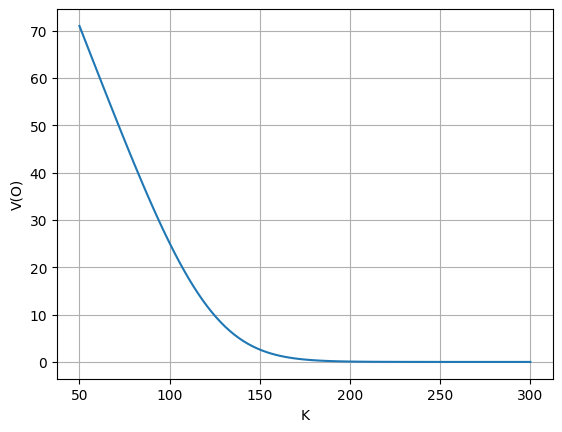

In [12]:
plt.plot(K_arr, call_Heston_FFT)
plt.ylabel('V(O)')
plt.xlabel('K')
plt.grid()
plt.show() # Should be same

<function matplotlib.pyplot.show(close=None, block=None)>

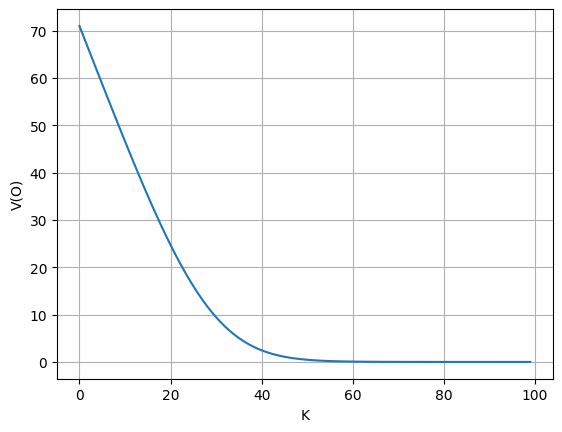

In [13]:
plt.plot(call_Heston_Laplace)
plt.ylabel('V(O)')
plt.xlabel('K')
plt.grid()
plt.show

We still need to measure the time that the FFT method needs in comparison to the time that we obtained in Task 1.3 for the Laplace transform method.

**Task 2.6**: Write a function `european_Heston_FFT(S0, K, T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho)` that performs the whole option pricing via FFT algorithm from Tasks 2.1 to 2.4 for multiple strike prices given as an input array `K` to the function.

In [15]:
def european_Heston_FFT(S0, K, T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho):
    K = np.atleast_1d(K)
    def f_k_tilde(z, kappa):
        return np.exp((1 - z) * kappa) / (z * (z - 1))

    def g(u):
        return f_k_tilde((R + (1j * u)), kappa = 0) * heston_char(u - 1j * R, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho)
    
    M = 5000
    N = 2 ** 16
    # FIX 1: Ensure kappa1 is a single scalar number by taking the minimum log-strike
    #kappa1 = np.log(np.min(K)) if isinstance(K, (np.ndarray, list)) else np.log(K)
    kappa1 = np.log(K[0])

    n = np.arange(1, N+1)
    kappa_m = kappa1 + (n - 1) * 2 * np.pi / M

    delta = M/N
    x = g((n - 0.5) * delta) * delta * np.exp(-1j * (n - 1) * delta * kappa1)
    x_hat = np.fft.fft(x)

    V_kappa_m = (np.exp(-r * T + (1 - R) * kappa_m) / np.pi) * np.real(x_hat * np.exp(-1j * 0.5 * delta * kappa_m))
    call_Heston_FFT = np.interp(K, np.exp(kappa_m), V_kappa_m)
    
    return call_Heston_FFT

# K = [] # can be set

print(european_Heston_FFT(S0, K, T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho))
# Slightly different, because N in the solution set to be 2 ** 16, instead of 2 ** 15

### Uncomment and execute the following line only if you obtained no result:
european_Heston_FFT1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_2_6.mar', 'rb')), globals())
print(european_Heston_FFT1(S0, K, T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho)) # OK

[6.32263316e-05]
[6.30890525e-05]


**Task 2.7**: Measure the time for an execution of the function `european_Heston_FFT` with strike prices given by the array `K_arr` and all other input variables as before using the command `%%timeit -n 10 -r 3` and compare the execution time to the execution time for the Laplace transform pricing obtained in Task 1.3.

<details>
  <summary>Result:</summary>
    <br>
    
Our timing result: `11.5 ms ± 18.7 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)`. Compared to the execution time of 503 ms of the Laplace transform method, the fast Fourier transform is over 40 times faster. This is because the Laplace transform approach is only capable of computing single option prices at a time while the fast Fourier transform computes the option prices for all considered strikes simultaneously.
</details>


In [16]:
%%timeit -n 10 -r 3
european_Heston_FFT(S0, K_arr[0], T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho)

# Interpretation: The FFT method processes the entire array of strikes simultaneously in a fraction of a second. 
# This vectorized O(N log N) transformation avoids the bottleneck of numerical integration (quad) used iteratively 
# in the standard Laplace approach.

23.7 ms ± 13.9 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)


<br>

## Step 3: Computation of sensitivities using the Laplace transform

Computing sensitivities of options with arbitrary (non-path dependent) payoffs is easy using the Laplace transform (see Section 3.3 in the lecture notes). We'd now like to compute $\frac{\partial}{\partial S(t)} V(t)$ (i.e. the delta of an option) for an option with arbitrary payoff in the Heston model.

**Task 3.1**: Define a function `delta_Heston(u, St, t, T, r, gamt, kappa, lamb, sig_tilde, rho)` that computes the derivative $\delta_t(u)$ of the Heston characteristic function $\chi_t(u)$ (given by the function `heston_char`) with respect to $S(t)$.

In [17]:
def delta_Heston(u, St, t, T, r, gamt, kappa, lamb, sig_tilde, rho):
#    delta = 1j * u * np.exp((1j * u - 1) * np.log(St) + 1j * u * r * (T - t) - ((1j * u) + (u ** 2)) * (sig_tilde ** 2) * 0.5 * (T - t))
    return 1j * u / St * heston_char(u, St, t, T, r, gamt, kappa, lamb, sig_tilde, rho)

# Take derivatives of the Heston_char with respect to St, using the Chain Rule

print(delta_Heston(120, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho))
### Uncomment and execute the following line only if you obtained no result:
delta_Heston1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_3_1.mar', 'rb')), globals())
print(delta_Heston1(120, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho))

(1.6092277566355646e-25+1.7738501581543673e-25j)
(1.6092277566355665e-25+1.7738501581543694e-25j)


**Task 3.2**: Use a for-loop and your function `delta_Heston` from Task 3.1 to compute the option delta $\frac{\partial}{\partial S(0)} V(0)$ for the European call in the Heston model with $K$ taking values in the array `K_arr` from Task 1.1. All other input variables should be as before. Store the result in an array `hedging_Heston_Laplace`.

*Useful Python commands*: `np.real`, `scipy.integrate.quad`, `np.exp`

In [18]:
hedging_Heston_Laplace = np.zeros(100)
# print(K_arr) # OK

for i, K in enumerate(K_arr): # Kalo ada i dia bisa keep track on the index of K in the K_arr
    def integrand(u):
            real =  np.real(f_tilde(R + 1j * u, K) * delta_Heston(u - 1j * R, S0, 0, T, r, gam0, kappa, lamb, sig_tilde, rho))
            return real
        
    hedging_Heston_Laplace[i] = np.exp(-r * T) / np.pi * quad(integrand, 0, np.inf)[0]

print(hedging_Heston_Laplace)

### Uncomment and execute the following line only if you obtained no result:
hedging_Heston_Laplace1 = np.loadtxt('../shared_materials/objects/3_3_2.txt')
print(hedging_Heston_Laplace1)
print(np.round(hedging_Heston_Laplace, 10) == np.round(hedging_Heston_Laplace1, 10)) # All True

[9.99165594e-01 9.98733582e-01 9.98124221e-01 9.97282924e-01
 9.96144086e-01 9.94630346e-01 9.92652123e-01 9.90107533e-01
 9.86882732e-01 9.82852772e-01 9.77883007e-01 9.71831099e-01
 9.64549643e-01 9.55889388e-01 9.45703041e-01 9.33849577e-01
 9.20198953e-01 9.04637098e-01 8.87071009e-01 8.67433749e-01
 8.45689134e-01 8.21835857e-01 7.95910816e-01 7.67991406e-01
 7.38196560e-01 7.06686391e-01 6.73660300e-01 6.39353554e-01
 6.04032348e-01 5.67987531e-01 5.31527200e-01 4.94968494e-01
 4.58628950e-01 4.22817835e-01 3.87827883e-01 3.53927820e-01
 3.21356033e-01 2.90315654e-01 2.60971222e-01 2.33446992e-01
 2.07826863e-01 1.84155781e-01 1.62442412e-01 1.42662826e-01
 1.24764895e-01 1.08673109e-01 9.42935431e-02 8.15187082e-02
 7.02321140e-02 6.03123780e-02 5.16367929e-02 4.40843012e-02
 3.75378710e-02 3.18862957e-02 2.70254676e-02 2.28591869e-02
 1.92995787e-02 1.62671898e-02 1.36908342e-02 1.15072535e-02
 9.66064548e-03 8.10211008e-03 6.78905001e-03 5.68455697e-03
 4.75680598e-03 3.978474

**Task 3.3**: Plot the values of $\frac{\partial}{\partial S(0)} V(0)$ against the values of $K$ stored in the array `K_array` and interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_3_3.png" width="550"><details>
  <summary>Interpretation:</summary> As usual for a European call option, the option delta starts at 1 for low values of the strike and decays in a sigmoid shape to 0 for large values of the strike. For low values of the strike, the instrinsic value of the call option much exceeds its continuation value so the price of the changes in the underlying induce almost perfectly equal changes in the option. If however the strike of the call option is large, the probability of the option terminating in the money becomes very small, so the option is worth almost nothing and its pricing curve flattens out, so the delta is almost equal to 0.

 </details>
</details>

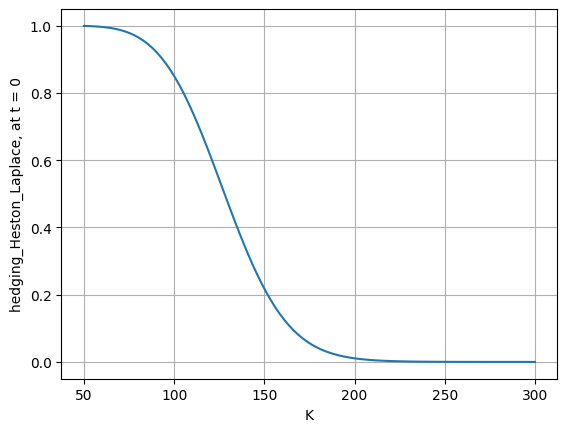

In [19]:
plt.plot(K_arr, hedging_Heston_Laplace)
plt.grid()
plt.xlabel('K')
plt.ylabel('hedging_Heston_Laplace, at t = 0')
plt.show()

# Interpretation: ...

We now want to compute the option delta dynamically in time for different values of $t$ than $t = 0$ but for the fixed strike $K = 100$. The code snippet below imports $N = 10\,000$ independent paths of the stock price process $S(t)$ and $N = 10\,000$ corresponding paths of the variance process $\gamma(t)$ in the Heston model at the $M = 1000$ time points $t = t_i = 0, \frac{1}{1000}, \frac{2}{1000}, \dots, \frac{999}{1000}, 1$. It afterwards extracts one of these stock price and variance paths, which we want to use in the upcoming tasks.

In [20]:
stock_paths = np.loadtxt('../shared_materials/data/Heston_paths.csv')
gamma_paths = np.loadtxt('../shared_materials/data/Heston_gamma.csv')

stock_path = stock_paths[0] # The first row of the data
gamma_path = gamma_paths[0] # The first row of the data
K = 100

print(stock_path)
print(gamma_path)

[120.         117.66764724 116.95176748 ... 128.55528479 129.57113165
 130.60141905]
[0.09       0.0923806  0.09280442 ... 0.03071958 0.03418691 0.03499242]


We are now ready to compute the option delta $\frac{\partial}{\partial S(t)} V(t)$ for $t = 0, \frac{1}{1000}, \frac{2}{1000}, \dots, \frac{999}{1000}$.

**Task 3.4**: Define a numpy array `t_arr` that contains the 1000 equally spaced values $t = 0, \frac{1}{1000}, \frac{2}{1000}, \dots, \frac{999}{1000}$. Then, use a for-loop to compute the option delta $\frac{\partial}{\partial S(t)} V(t)$ for the European call in the Heston model for $t$ taking values in the array `t_arr`. Store your option deltas in an array `delta_Heston_arr`.

In [21]:
t_arr = np.linspace(0, 999, 1000) / 1000
#print(len(t_arr))

delta_Heston_arr = np.zeros(1000)

for i in range(1000):
    def integrand(u):
        real =  np.real(f_tilde(R + 1j * u, K) * delta_Heston(u - 1j * R, stock_path[i], 
                    t_arr[i], T, r, gamma_path[i], kappa, lamb, sig_tilde, rho))
        
        return real
        
    delta_Heston_arr[i] = np.exp(-r * (T - t_arr[i])) / np.pi * quad(integrand, 0, np.inf)[0]

print(len(delta_Heston_arr)) # OK

### Uncomment and execute the following line only if you obtained no result:
t_arr1, delta_Heston_arr1 = np.loadtxt('../shared_materials/objects/3_3_4.txt')
print(len(t_arr1))
print(np.round(t_arr, 10) == np.round(t_arr1, 10)) # All True
#print(len(delta_Heston_arr1))
print(np.round(delta_Heston_arr, 10) == np.round(delta_Heston_arr1, 10)) # All True

1000
1000
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  Tru

**Task 3.5**: Plot the option deltas $\frac{\partial}{\partial S(t)} V(t)$ against $t$ and interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_3_5.png" width="550"><details>
  <summary>Interpretation:</summary> The delta of the call option fluctuates in the early stages of the lifetime of the option before it approaches the constant value 1 prior to maturity. This is the case because the stock price approaches a value above the strike $K = 100$ as $t$ tends to 1, so the call option finishes in the money and the sensitivity of the option price with respect to $S(t)$ converges to the derivative of the option's payoff with respect to $S(T)$. If the stock price had approached a value below the strike $K = 100$ as $t \to 1$, the delta of the option would have approached 0.

 </details>
</details>

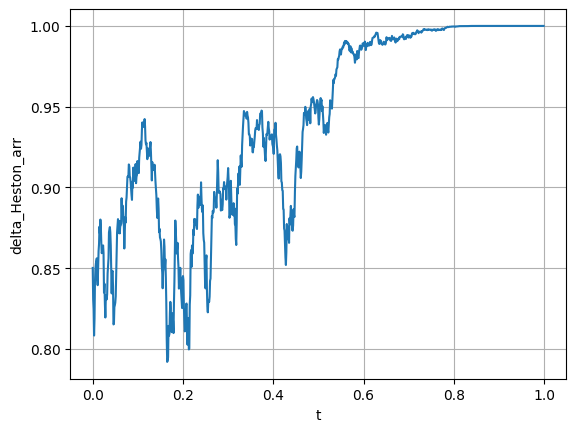

In [23]:
plt.plot(t_arr, delta_Heston_arr)
plt.grid()
plt.xlabel('t')
plt.ylabel('delta_Heston_arr')
plt.show()

# Interpretation: ...

<br> 

## Step 4: Computation of barrier option prices using the multivariate Laplace transform

If the payoff $X$ of an option at time $T$ depends on more random variables than just the log-stock price $X(T)$, one can try to use a multivariate extension of the Laplace transform method to come up with option prices. This is for example the case for barrier options like a *down-and-out call option* with payoff $(S(T) - K)^+ \mathbf{1}_{\{M(T) \geq B\}}$, where $M(T) = \min_{t \leq T} S(t)$ denotes the running minimum of the stock price. To evaluate prices of such barrier options, we need the joint characteristic function of $(X(T), \log(M(T)))$, which is fortunately available in closed form in the Black&ndash;Scholes model with volatility $\sigma$. It evaluates to
\begin{equation}
\widehat{\chi}(u, v) = E_Q(e^{iuX(T) + iv\log(M(T))}) = \exp\Big(i(u + v) \log S(0) - \frac{\nu^2 T}{2 \sigma^2}\Big) \frac{(\nu + \sigma^2 i (u + v)) w(d(u + v)) + (\nu + \sigma^2 i u) w(-d(u))}{2 \nu + \sigma^2 i (2 u + v)}, \tag{1}
\end{equation}
where $\nu = r - \frac{1}{2}\sigma^2$, $d(u) = (i \frac{\nu}{\sigma} - \sigma u) \sqrt{\frac{T}{2}}$ and where $w(z) = e^{-z^2}\mathrm{erfc}(-iz)$ denotes the *Faddeeva function*. The code snippet below contains a function `chi_hat(u, v, S0, T, r, sigma)` that computes $\widehat{\chi}(u, v)$ from equation (1) above.

In [24]:
def chi_hat(u, v, S0, T, r, sigma): # Faddeeva function
    nu = r - 0.5 * sigma**2
    
    d_uv = (1j * nu / sigma - sigma * (u + v)) * np.sqrt(T / 2)
    d_u  = (1j * nu / sigma - sigma * u) * np.sqrt(T / 2)

    term1 = (nu + sigma**2 * 1j * (u + v)) * wofz(d_uv)
    term2 = (nu + sigma**2 * 1j * u) * wofz(-d_u)

    denom = 2 * nu + sigma**2 * 1j * (2 * u + v)
    return np.exp(1j * (u + v) * np.log(S0) - nu**2 * T / (2 * sigma**2)) * (term1 + term2) / denom

Recall from Exercise 05.1 on Homework Sheet 05 that the multivariate bilateral Laplace transform of the payoff $f(x, m) = (e^x - K)^+ \mathbf{1}_{\{e^m \geq B\}}$ is given by $\widetilde f(z_1, z_2) = \frac{B^{-z_2} K^{1 - z_1}}{z_1 z_2 (z_1 - 1)}$ for $\mathrm{Re}(z_1) > 1$ and $\mathrm{Re}(z_2) > 0$.

**Task 4.1**: Write a function `f_tilde(z1, z2, K, B)` that implements the above multivariate Laplace transform and takes the stike $K$ and the barrier $B$ as additional inputs.

In [25]:
def f_tilde(z1, z2, K, B):
    return ((B ** (-z2)) * (K ** (1 - z1))) / (z1 * z2 * (z1 - 1))

print(f_tilde(21, 16, 17, 49)) # OK

### Uncomment and execute the following line only if you obtained no result:
f_tilde1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_4_1.mar', 'rb')), globals())
print(f_tilde1(21, 16, 17, 49))

3.3152403449433376e-56
3.3152403449433376e-56


Given the multivariate Laplace transform $\widetilde f(z_1, z_2)$ of the bivariate payoff function $f$ and the joint characteristic function $\widehat \chi$ from equation (1) above, we can obtain the price $V(0)$ of a down-and-out call option using the multivariate inverse Laplace transform via
\begin{equation}
V(0) = \frac{e^{-rT}}{4 \pi^2} \int\limits_{-\infty}^\infty \int\limits_{-\infty}^\infty \widetilde f(R_1 + iu, R_2 + iv) \widehat \chi(u - iR_1, v - iR_2) dv \,du \tag{2}
\end{equation}
for $R_1 > 1$ and $R_2 > 0$.

**Task 4.2**: Use the scipy.integrate function `dblquad` to evaluate the double integral (2) above and compute the price $V(0)$ of the barrier option with $K = 100$, $B = 100$ and $\sigma = 0.3$. Choose appropriate values of $R_1$ and $R_2$ for the integration. Print the resulting barrier option price and compare it to your result from Notebook 01, Task 4.3.

*Useful Python commands*: The double integral $\int_c^d \int_a^b f(u, v) dv\, du$ can be computed via the command `dblquad(f, a, b, c, d)[0]`. `a` `b`, `c` or `d` can also be set to `np.inf`. 

In [26]:
R1 = 1.5
R2 = 0.5
sigma = 0.3
K = 100
B = 100

def integrand(u, v):
        real =  np.real(f_tilde(R1 + 1j * u, R2 + 1j * v, K, B) * chi_hat(u - 1j * R1, v - 1j * R2, S0, T, r, sigma))
        return real
        
V0 = np.exp(-r * T) / (4 * (np.pi ** 2)) * dblquad(integrand, -np.inf, np.inf, -np.inf, np.inf)[0]

print('The price of the down-and-out call option is {}'.format(V0))

### Uncomment and execute the following line only if you obtained no result:
# V0 = 21.265548377421933 # OK with R1 = 1.5 and R2 = 0.5. Does it effect the results? OK 
# The V0 is roughly the same with the V0 on barrier_prices_CRR. Notebook 01, Task 4.3 

The price of the down-and-out call option is 21.265548377421933


<br>

## Step 5: Calibration of the Heston model to S&P 500 call options using implied volatility

Calibration of an option pricing model, i.e. fitting the parameters of the model to real market data of options, is one of the most important tasks in computational finance. The following code snippet imports a dataset of European call options on the S&P 500 index on 06 September 2022 with expiry on 30 December 2022 (this corresponds to a time-to-maturity of approximately 0.3194 years). The dataset contains both the bid and ask price of the options, the midpoint between bid and ask price and the bid-ask spread for 320 different strikes. It also contains the underlying S&P 500 level on 06 September 2022 as well as the LIBOR rate as a proxy for the risk-free interest rate, which was interpolated to the time to maturity of the option. 

* LIBOR, which stands for London Interbank Offered Rate, was a benchmark interest rate used globally to guide short-term lending between banks.

In [27]:
options = pd.read_csv('../shared_materials/data/options_SP500.csv')
pd.DataFrame(options)

,Strike,Bid,Midpoint,Ask,Expiry,Spread,TTM,Underlying,Interest
0,3025.0,919.00,921.20,923.40,2022-12-30,4.40,0.319444,3908.189941,0.024678
1,3050.0,895.50,897.70,899.90,2022-12-30,4.40,0.319444,3908.189941,0.024678
2,3060.0,886.80,888.90,891.00,2022-12-30,4.20,0.319444,3908.189941,0.024678
3,3070.0,877.70,879.80,881.90,2022-12-30,4.20,0.319444,3908.189941,0.024678
4,3075.0,872.80,874.95,877.10,2022-12-30,4.30,0.319444,3908.189941,0.024678
...,...,...,...,...,...,...,...,...,...
315,5150.0,0.35,0.48,0.60,2022-12-30,0.25,0.319444,3908.189941,0.024678
316,5175.0,0.30,0.40,0.50,2022-12-30,0.20,0.319444,3908.189941,0.024678
317,5200.0,0.25,0.35,0.45,2022-12-30,0.20,0.319444,3908.189941,0.024678
318,5225.0,0.20,0.30,0.40,2022-12-30,0.20,0.319444,3908.189941,0.024678


The option dataset was imported as a pandas dataframe, which is sometimes handier than using a numpy array to work with data matrices.

**Task 5.1**: Use the `.head()` method of the pandas dataframe to print the first few lines of the dataframe `options`.


<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_5_1.png" width="550">
</details>

In [28]:
pd.DataFrame.head(options)

,Strike,Bid,Midpoint,Ask,Expiry,Spread,TTM,Underlying,Interest
0,3025.0,919.0,921.20,923.4,2022-12-30,4.4,0.319444,3908.189941,0.024678
1,3050.0,895.5,897.70,899.9,2022-12-30,4.4,0.319444,3908.189941,0.024678
2,3060.0,886.8,888.90,891.0,2022-12-30,4.2,0.319444,3908.189941,0.024678
3,3070.0,877.7,879.80,881.9,2022-12-30,4.2,0.319444,3908.189941,0.024678
4,3075.0,872.8,874.95,877.1,2022-12-30,4.3,0.319444,3908.189941,0.024678


**Task 5.2**: Define variables `sp500`, `ttm` and `libor` that contain the level of the S&P 500 at 06 September 2022, the time to maturity of the options in the dataset and the risk-free interest rate from the dataset, respectively. Then, define a numpy array `strikes` and a numpy array `prices` that contain the values of the `'Strike'` column and of the `'Midpoint'` column, respectively.

*Useful Python commands*: To cast a pandas dataframe or the column of a dataframe to a numpy array, use `.values` on the dataframe/the column.

In [29]:
sp500 = options['Underlying'].iloc[0] # Parshing values of Underlying at the position 0
ttm = options['TTM'].iloc[0]
libor = options['Interest'].iloc[0]

print(sp500, ttm, libor) # OK

strikes = options['Strike'].values
prices = options['Midpoint'].values

print(strikes, prices)


### Uncomment and execute the following lines only if you obtained no result:
# sp500, ttm, libor = 3908.18994140625, 0.3194444444444444, 0.0246783046022779 # OK
strikes1, prices1 = np.loadtxt('../shared_materials/objects/3_5_2.txt')
#print(strikes1, prices1)
print(np.array_equal(strikes1, strikes)) # True
print(np.array_equal(prices1, prices)) # True

3908.18994140625 0.3194444444444444 0.0246783046022779
[3025. 3050. 3060. 3070. 3075. 3080. 3090. 3100. 3110. 3120. 3125. 3130.
 3140. 3150. 3160. 3170. 3175. 3180. 3190. 3200. 3210. 3220. 3225. 3230.
 3240. 3250. 3260. 3270. 3275. 3280. 3290. 3300. 3310. 3320. 3325. 3330.
 3340. 3350. 3360. 3365. 3370. 3375. 3380. 3385. 3390. 3395. 3400. 3405.
 3410. 3415. 3420. 3425. 3430. 3435. 3440. 3445. 3450. 3455. 3460. 3465.
 3470. 3475. 3480. 3485. 3490. 3495. 3500. 3505. 3510. 3515. 3520. 3525.
 3530. 3535. 3540. 3545. 3550. 3555. 3560. 3565. 3570. 3575. 3580. 3585.
 3590. 3595. 3600. 3605. 3610. 3615. 3620. 3625. 3630. 3635. 3640. 3645.
 3650. 3655. 3660. 3665. 3670. 3675. 3680. 3685. 3690. 3695. 3700. 3705.
 3710. 3715. 3720. 3725. 3730. 3735. 3740. 3745. 3750. 3755. 3760. 3765.
 3770. 3775. 3780. 3785. 3790. 3795. 3800. 3805. 3810. 3815. 3820. 3825.
 3830. 3835. 3840. 3845. 3850. 3855. 3860. 3865. 3870. 3875. 3880. 3885.
 3890. 3895. 3900. 3905. 3910. 3915. 3920. 3925. 3930. 3935. 3940. 39

A possible way to calibrate the parameters of a stochastic model like the Heston model is to minimize the sum of squared errors between the model option prices $V_i(0)$ and the actual market-observed option prices $\pi_i$ as in equation (3.19) in the lecture notes. Often in practice, it is however preferred to calibrate model parameters to so-called ***implied volatilities*** instead of to the option prices:

The Black–Scholes formula establishes a one-to-one correspondence between the volatility $\sigma$ and the initial price $V(0)$ of a European call option if all other input variables are fixed. Instead of computing the call option price $V(0)$ from a given volatility $\sigma$, one can therefore also invert the order and compute the proper value of $\sigma$ from a given call option price $V(0)$. This is called the *implied volatility* of an option. Think of implied volatilities as just another way to quote option prices: In the same way as one can quote stock returns either as percentage returns or as logarithmic returns (with the possibility to convert each of the two to the other), one can quote option prices either using the actual price or using the implied volatility. 

Quoting option prices as implied volatilities has the advantage that it is a dimensionless way to view the value of an option: If e.g. from one day to another the value of a call option increases by 10 dollars, it is not ad hoc clear whether this change originates just from an increase in the underlying or if the option really got relatively more expensive compared to the underlying. If however the implied volatility of a call option increases from one day to another, one can immediately conclude that the option got relatively more expensive compared to the underlying, no matter whether the actual option price increased or decreased during that period of time.

In the following we will define a function that computes the implied volatility from an option price.

**Task 5.3**: Copy your function `european_BS(t, St, K, T, r, sigma, call)` that computes European option prices in the Black&ndash;Scholes model from Task 1.5 of Notebook 02, or write it from scratch if you did not complete that task from Notebook 02.

In [30]:
from scipy.stats import norm

def european_BS(t, St, K, T, r, sigma, call):

    d1 = (np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))
    
    d2 = (np.log(St/K) + (r - sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))

    # Put-Call-Parity
    if call == 1:
        return St * norm.cdf(d1) - K * np.exp(-r * (T - t)) * norm.cdf(d2)
        
    elif call == 0:
        return K * np.exp(-r * (T - t)) * norm.cdf(-d2) - St * norm.cdf(-d1)

print(european_BS(t = 0, St = 134, K = 273, T = 1, r = 0.02, sigma = 0.3, call = 0))

### Uncomment and execute the following line only if you obtained no result:
european_BS1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_5.mar', 'rb')), globals())
print(european_BS1(t = 0, St = 134, K = 273, T = 1, r = 0.02, sigma = 0.3, call = 0)) # OK

133.79708565533025
133.79708565533025


The following code snippet contains a function `ImpVol(V0, S0, r, T, K)` that returns the implied volatility corresponding to an option price `V0` with underlying `S0`, risk-free interest rate `r`, time to maturity `T` and strike `K`. The function uses Chandrupatla’s bracketing algorithm from the `scipy.optimize.elementwise` function `find_root` to find the implied volatility. The advantage of this function is that you can supply a whole numpy array for the input arguments `V0` and `K` to simultaneously compute the implied volatility for multiple options with different strike prices. If the input argument `call` is set to 1, the function assumes that the prices in `V0` are call option prices, if it is set to 0, the function assumes that they are put option prices.

In [31]:
def ImpVol(V0, S0, r, T, K, call):
    def objective(sigma, K, V0):
        return european_BS(0, S0, K, T, r, sigma, call=call) - V0
    lower = np.repeat(1e-12, np.size(K))
    upper = np.repeat(5, np.size(K))
    return find_root(objective, (lower, upper), args=(K, V0)).x

**Task 5.4**: Use the above function `ImpVol` to compute the implied volatilities of the market-quoted S&P 500 call option prices from the array `prices` and store them in an array `impvols`. Afterwards, plot the implied volatilites against the strike prices from the array `strikes`. Interpret your result using a comment. Why is the Black&ndash;Scholes model not suitable to model this data set of S&P 500 options?

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_5_4.png" width="550"><details>
  <summary>Interpretation:</summary> The S&P 500 options display a volatility skew that is characteristic for stock and index options, that is, the options possess a high implied volatility for low strikes that decreases and flattens out at high strikes. This shows that the Black&ndash;Scholes model is not well-suited to model the S&P 500 options because by construction, the implied volatility curve of the same options in the Black&ndash;Scholes model would be a straight line, not a skew. No matter what value of the volatility $\sigma$ one uses in the BlackScholes model, the low-strike S&P 500 options would always be underpriced compared to the high-strike S&P 500 options. For very low and very high values of the strike, the implied volatility curve becomes somewhat rough and unstable, which is a result of the lower trading volume of these options.

 </details>
</details>

320
320
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True 

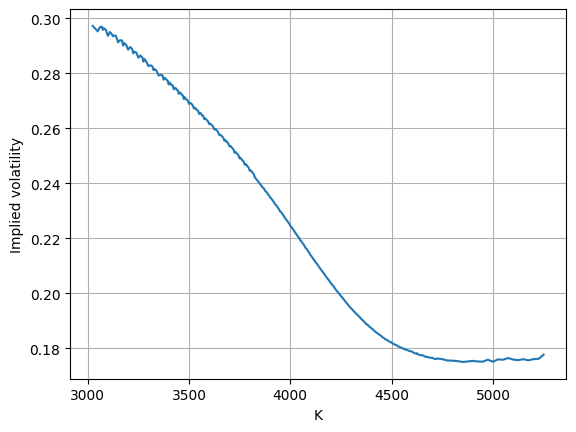

In [32]:
impvols = ImpVol(prices, sp500, libor, ttm, strikes, call = 1)
print(len(impvols))

### Uncomment and execute the following line only if you obtained no result:
impvols1 = np.loadtxt('../shared_materials/objects/3_5_4.txt')
print(len(impvols1))

print(np.round(impvols, 10) == np.round(impvols1, 10)) # All True

plt.plot(strikes, impvols)
plt.grid()
plt.xlabel('K')
plt.ylabel('Implied volatility')
plt.show()

# Interpretation: ...

Due to the advantages of using implied volatility as a dimensionless way to quote option prices, it is generally also preferrable calibrate model parameters to implied volatilites by minimizing the sum of squared implied volatility errors $\sum_{i=1}^n \big[\mathrm{IV}(\pi_i) - \mathrm{IV}(V_i(0))\big]^2$, where $\mathrm{IV}(\pi_i)$ denotes the implied volatility of the market-observed options and $\mathrm{IV}(V_i(0))$ denotes the implied volatility of the options in the stochastic model. We first need a function that computes the latter in the Heston model.

**Task 5.5**: Write a function `ImpVol_Heston(S0, K, T, r, R, gam0, kappa, lamb, sig_tilde, rho)` that accepts an array `K` of strike prices as an input and then first computes the array of corresponding European call option prices in the Heston model using the function `european_Heston_FFT` from Task 2.6 with $M = 5000$ and $N = 2^{15}$. Afterwards, it should return the implied volatility corresponding to these Heston call option prices by using the function `ImpVol` from above.

In [33]:
def ImpVol_Heston(S0, K, T, r, R, gam0, kappa, lamb, sig_tilde, rho):
    heston_prices = european_Heston_FFT(S0, K, T, r, R, M, N, gam0, kappa, lamb, sig_tilde, rho)
    
    return ImpVol(heston_prices, S0, r, T, K, call = 1)

print(ImpVol_Heston(S0, K, T, r, R, gam0, kappa, lamb, sig_tilde, rho))

### Uncomment and execute the following line only if you obtained no result:
ImpVol_Heston1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_5_5.mar', 'rb')), globals())
print(ImpVol_Heston1(S0, K, T, r, R, gam0, kappa, lamb, sig_tilde, rho)) # [0.24788566] OK

[0.24788566]
[0.24788566]


**Task 5.6**: Write a function `min_func(params)` that is supposed to be passed to the scipy `minimize` routine (see the code cell one further below). The function should accept an array `params` as an argument that contain the parameters $\gamma(0), \kappa, \lambda, \widetilde \sigma$ and $\rho$ in this order. It should then compute the Heston model implied volatilities corresponding to these parameters and to the options with strike prices given by the array `strikes` from the dataset using the function `ImpVol_Heston` with $R = 1.5$. Finally it should return the mean squared error $\frac{1}{n}\sum_{i=1}^n \big[\mathrm{IV}(\pi_i) - \mathrm{IV}(V_i(0))\big]^2$ between the Heston model implied volatilities and the market implied volatilities from the array `impvols`.

*Remark*: The given code at the end of the function will print a callback during the minimization process in the next task. You can leave it as it is.

In [36]:
initial_params = np.array([0.05, 0.05, 0.5, 0.3, -0.5])
def min_func(params):
    gam0, kappa, lamb, sig_tilde, rho = params
    
    # Calculate differences between market-observed IV & model IV (R = 1.5)
    heston_model_IV = ImpVol_Heston(sp500, strikes, ttm, libor, 1.5, gam0, kappa, lamb, sig_tilde, rho)
    mse = np.mean((impvols - heston_model_IV) ** 2)

    ### Callback section
    global it
    clear_output(wait=True)
    print('It: {:4d},  '.format(it) + ''.join([name + ' = {:.4e}, '.format(param) for name, param in zip(['gamma_0', 'kappa', 'lambda', 'sigma_tilde', 'rho'], params)]) + 'MSE = {:.6e}'.format(mse))
    it += 1
    ###
    return mse
    
print(min_func(initial_params))

### Uncomment and execute the following line only if you obtained no result:
min_func1 = types.FunctionType(marshal.load(open('../shared_materials/objects/3_5_6.mar', 'rb')), globals())
print(min_func1(initial_params))

It:  362,  gamma_0 = 5.0000e-02, kappa = 5.0000e-02, lambda = 5.0000e-01, sigma_tilde = 3.0000e-01, rho = -5.0000e-01, MSE = 4.702313e-04
0.0004702313492683817


The code snippet below now performs the minimization of the implied volatility mean squared error using the scipy.optimize routine `minimize`. A very solid first choice for a minimization algorithm is often the Nelder-Mead algorithm, so we also use it below. The minimization uses the initial parameter guess $\gamma(0) = \kappa = 0.05$, $\lambda = 0.5$, $\widetilde \sigma = 0.3$, $\rho = -0.5$ and also specifies bounds for the five parameters.

*Remark*: Calibration of parameters in the Heston model to options with a single maturity is very sensitive to the chosen initial guess of parameters. Different initial guesses may lead to different fitted parameters because the scipy minimize routine might get stuck in a suboptimal local minimum.

In [35]:
it = 1
initial_params = np.array([0.05, 0.05, 0.5, 0.3, -0.5])
bounds = [[1e-15, 2], [1e-15, 2], [1e-15, 10], [1e-15, 1], [-0.999, 0.999]]
fitted_params = minimize(min_func, initial_params, bounds=bounds, method='Nelder-Mead').x
print(fitted_params)

It:  360,  gamma_0 = 6.2958e-02, kappa = 4.6109e-06, lambda = 4.5464e-01, sigma_tilde = 4.5430e-01, rho = -7.3260e-01, MSE = 5.940794e-06
[ 6.29577929e-02  4.61086232e-06  4.54636128e-01  4.54302334e-01
 -7.32604851e-01]


**Task 5.7**: Use the function `ImpVol_Heston` from Task 5.5 to compute both the Heston model implied volatilies corresponding to the initial parameter guess (from the array `initial_params`) and to the fitted parameters (from the array `fitted_params`). Store these in arrays `impvol_model_init` and `impvol_model_fitted`, respectively. Afterwards, use the function `european_Heston_FFT` to compute both the heston model prices corresponding to the initial parameter guess and to the fitted parameters and store them in arrays `prices_model_init` and `prices_model_fitted`, respectively.

In [37]:
impvol_model_init = ImpVol_Heston(sp500, strikes, ttm, libor, 1.5, 0.05, 0.05, 0.5, 0.3, -0.5)
#print(impvol_model_init)
impvol_model_fitted = ImpVol_Heston(sp500, strikes, ttm, libor, 1.5, *fitted_params)
#print(impvol_model_fitted)

prices_model_init = european_Heston_FFT(sp500, strikes, ttm, libor, 1.5, 5000, 2 ** 16, *initial_params)
prices_model_fitted = european_Heston_FFT(sp500, strikes, ttm, libor, 1.5, 5000, 2 ** 16, *fitted_params)

#print(prices_model_init)
print(prices_model_fitted)

### Uncomment and execute the following line only if you obtained no result:
impvol_model_init1, impvol_model_fitted1, prices_model_init1, prices_model_fitted1 = np.loadtxt('../shared_materials/objects/3_5_7.txt')
#print(impvol_model_init1)
#print(impvol_model_fitted1)
#print(impvol_model_fitted1)
#print(np.round(impvol_model_init, 4) == np.round(impvol_model_init1, 4)) # All True
#print(np.round(impvol_model_fitted1, 1) == np.round(impvol_model_fitted, 1)) # All True

#print(prices_model_init1)
print(prices_model_fitted1)

#print(np.round(prices_model_init) == np.round(prices_model_init1)) # All True
print(np.round(prices_model_fitted) == np.round(prices_model_fitted1)) # Many Trues, but I think it should be fine?? It's should be fine

[9.23516244e+02 9.00156696e+02 8.90842159e+02 8.81545322e+02
 8.76903356e+02 8.72266351e+02 8.63005418e+02 8.53763664e+02
 8.44540508e+02 8.35337511e+02 8.30743141e+02 8.26154078e+02
 8.16991410e+02 8.07849461e+02 7.98728983e+02 7.89630323e+02
 7.85089434e+02 7.80553954e+02 7.71500431e+02 7.62470147e+02
 7.53463651e+02 7.44481488e+02 7.39999327e+02 7.35523945e+02
 7.26591993e+02 7.17685369e+02 7.08805777e+02 6.99952189e+02
 6.95536199e+02 6.91127041e+02 6.82329127e+02 6.73560071e+02
 6.64820117e+02 6.56109235e+02 6.51765694e+02 6.47429580e+02
 6.38779920e+02 6.30162008e+02 6.21576249e+02 6.17295256e+02
 6.13022288e+02 6.08758170e+02 6.04502567e+02 6.00255228e+02
 5.96016227e+02 5.91785644e+02 5.87563554e+02 5.83351117e+02
 5.79147356e+02 5.74952336e+02 5.70766135e+02 5.66588833e+02
 5.62420511e+02 5.58262272e+02 5.54113263e+02 5.49973487e+02
 5.45843025e+02 5.41721959e+02 5.37610371e+02 5.33508847e+02
 5.29417578e+02 5.25336048e+02 5.21264340e+02 5.17202539e+02
 5.13150730e+02 5.091089

**Task 5.8**: Plot the marked-observed implied volatilites (from the array `impvols`), the initial guess implied volatilities (from the array `impvol_model_init`) and the fitted model implied volatilities (from the array `impvol_model_fitted`) in a common plot. Repeat this for the prices instead of implied volatilities in a separate plot window. Interpret your result using a comment. What are the advantages of fitting parameters to implied volatilities instead of prices?

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/3_5_8.png" width="950"><details>
  <summary>Interpretation:</summary> The plot on the left shows that the implied volatility curve using the fitted Heston parameters (the green line) adequately interpolates the market-implied volatility curve (the blue line). Compared to the fitted volatility, the implied volatility curve corresponding to the initial guess of parameters (the orange line) is much too flat. Only for very low strike values, where the market-implied volatility curve flattens a bit out, the Heston model is not perfectly able to capture the implied volatility behaviour of the S&P 500. By looking at the fit of option prices on the right, it becomes apparent why it is useful to employ implied volatilities for fitting parameters: At first glance it seems that even the initial guess of parameters (the orange line) provides a very good fit to the option prices in the market (the blue line), even though the implied volatility fit on the left clearly displays the opposite. Since call option prices will always tend to be nearly zero for strikes well above the underlying and will always tend to behave almost linearly for strikes well below the underlying, it cannot really be assessed from looking only at the price curves which of these options are relatively expensive and which of them are relatively cheap. This can only be done be examining the implied volatility.

 </details>
</details>

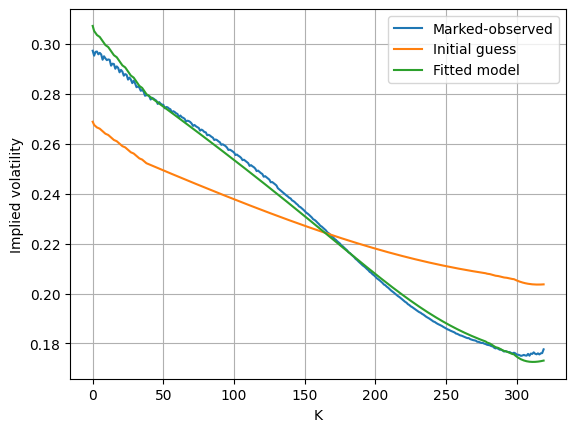

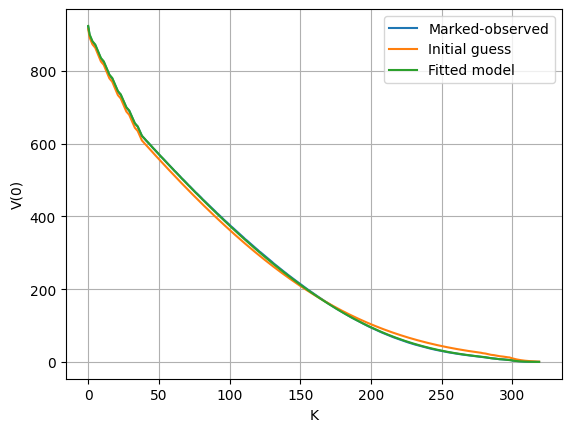

In [38]:
plt.plot(impvols, label = 'Marked-observed')
plt.plot(impvol_model_init, label = 'Initial guess')
plt.plot(impvol_model_fitted, label = 'Fitted model')
plt.grid()
plt.ylabel('Implied volatility')
plt.xlabel('K')
plt.legend()
plt.show()

plt.plot(prices, label = 'Marked-observed')
plt.plot(prices_model_init, label = 'Initial guess')
plt.plot(prices_model_fitted, label = 'Fitted model')
plt.ylabel('V(0)')
plt.xlabel('K')
plt.grid()
plt.legend()
plt.show()

# Interpretation: ...